# 

In [1]:
import glob
import h5py

# Find all NISAR files in data/raw (sorted by name: 033_167 = 23 Oct BEFORE, 034_058 = 28 Oct AFTER)
files = sorted(glob.glob("../data/raw/*.h5"))
for path in files:
    print(path.split("/")[-1])

# Open the first file (BEFORE) in read-only mode
f = h5py.File(files[0], "r")

# List only the images (2D datasets) inside "grids"
def show_images(name, obj):
    if isinstance(obj, h5py.Dataset) and obj.ndim == 2 and "grids" in name:
        print(f"{name:60s} {obj.shape}  {obj.dtype}")

f.visititems(show_images)

NISAR_L2_PR_GCOV_033_167_D_069_2005_DHDH_A_20261023T190137_20261023T190212_P05036_N_F_J_001.h5
NISAR_L2_PR_GCOV_034_058_A_022_2005_DHDH_A_20261028T050718_20261028T050753_P05036_N_F_J_001.h5
science/LSAR/GCOV/grids/frequencyA/HHHH                      (17352, 17604)  float32
science/LSAR/GCOV/grids/frequencyA/HVHV                      (17352, 17604)  float32
science/LSAR/GCOV/grids/frequencyA/inputDataExceptionMask    (17352, 17604)  uint16
science/LSAR/GCOV/grids/frequencyA/mask                      (17352, 17604)  uint8
science/LSAR/GCOV/grids/frequencyA/numberOfLooks             (17352, 17604)  float32
science/LSAR/GCOV/grids/frequencyA/rtcGammaToSigmaFactor     (17352, 17604)  float32
science/LSAR/GCOV/grids/frequencyB/HHHH                      (4338, 4401)  float32
science/LSAR/GCOV/grids/frequencyB/HVHV                      (4338, 4401)  float32
science/LSAR/GCOV/grids/frequencyB/inputDataExceptionMask    (4338, 4401)  uint16
science/LSAR/GCOV/grids/frequencyB/mask                

In [2]:
# Read the "identity card" of each file
def read_text(dataset):
    value = dataset[()]                      # read the stored value
    return value.decode() if isinstance(value, bytes) else value

for path in files:
    with h5py.File(path, "r") as nisar:
        ident = nisar["science/LSAR/identification"]
        print("File      :", path.split("/")[-1][:45], "...")
        print("Start time:", read_text(ident["zeroDopplerStartTime"]))
        print("Track     :", read_text(ident["trackNumber"]))
        print("Frame     :", read_text(ident["frameNumber"]))
        print("Direction :", read_text(ident["orbitPassDirection"]))
        print("Look side :", read_text(ident["lookDirection"]))
        print("Product   :", read_text(ident["productType"]))
        print("-" * 60)

File      : NISAR_L2_PR_GCOV_033_167_D_069_2005_DHDH_A_20 ...
Start time: 2026-10-23T19:01:37.000000000
Track     : 167
Frame     : 69
Direction : Descending
Look side : Left
Product   : GCOV
------------------------------------------------------------
File      : NISAR_L2_PR_GCOV_034_058_A_022_2005_DHDH_A_20 ...
Start time: 2026-10-28T05:07:18.000000000
Track     : 58
Frame     : 22
Direction : Ascending
Look side : Left
Product   : GCOV
------------------------------------------------------------


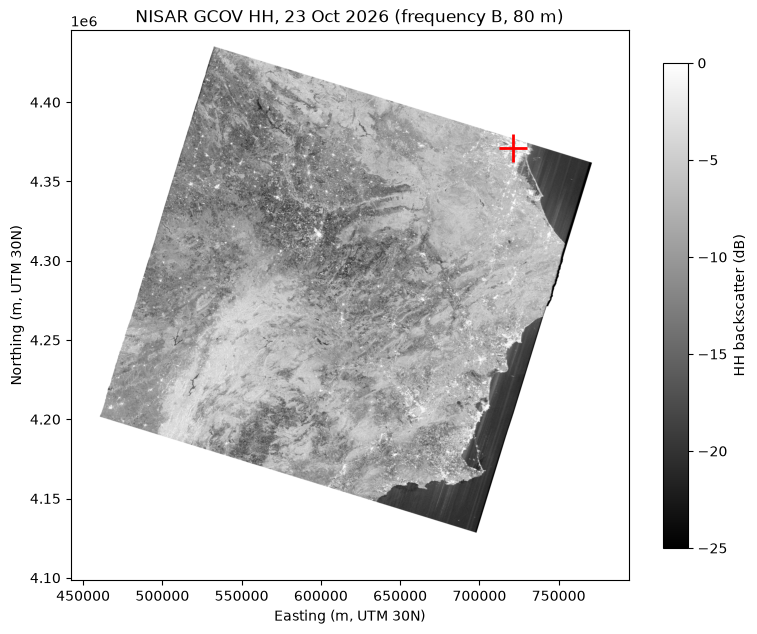

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from pyproj import Transformer

# 1. Read the HH image from frequency B (80 m pixels, ~76 MB) + its coordinates
grid = f["science/LSAR/GCOV/grids/frequencyB"]
hh = grid["HHHH"][:]
x = grid["xCoordinates"][:]
y = grid["yCoordinates"][:]
epsg = int(grid["projection"].attrs["epsg_code"])   # map system of the file (UTM zone 30N)

# 2. Convert power to decibels (ignore empty pixels: 0 or NaN)
hh_db = 10 * np.log10(np.where(hh > 0, hh, np.nan))

# 3. Convert Valencia lat/lon to the same map system as the image
to_map = Transformer.from_crs("EPSG:4326", f"EPSG:{epsg}", always_xy=True)
valencia_x, valencia_y = to_map.transform(-0.4275, 39.46)

# 4. Draw the image + a red cross on Valencia
plt.figure(figsize=(9, 9))
plt.imshow(hh_db, cmap="gray", vmin=-25, vmax=0, extent=[x[0], x[-1], y[-1], y[0]])
plt.colorbar(label="HH backscatter (dB)", shrink=0.7)
plt.plot(valencia_x, valencia_y, "r+", markersize=20, markeredgewidth=2)
plt.title("NISAR GCOV HH, 23 Oct 2026 (frequency B, 80 m)")
plt.xlabel("Easting (m, UTM 30N)")
plt.ylabel("Northing (m, UTM 30N)")
plt.show()

Crop size (rows, cols): (983, 1446)


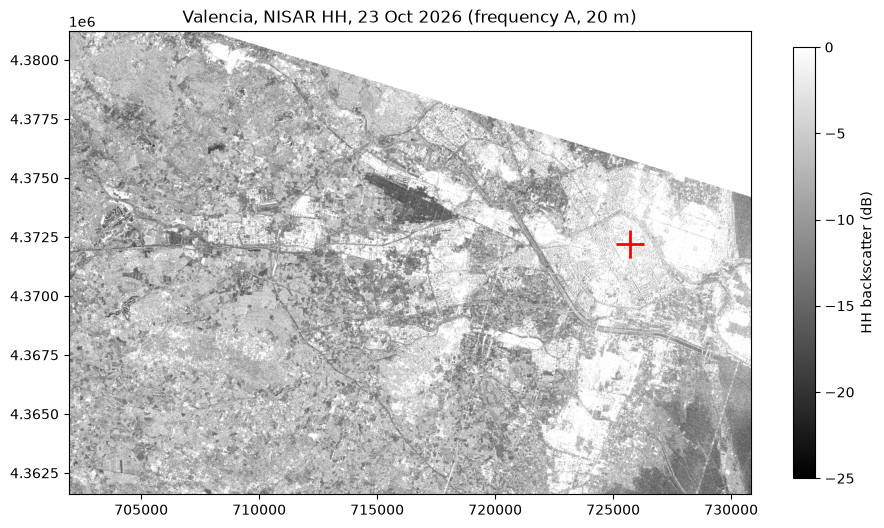

In [4]:
# Area of interest: Valencia city (lon_min, lat_min, lon_max, lat_max)
# Chosen so that BOTH scenes cover ~86% of it
BBOX = (-0.65, 39.38, -0.32, 39.55)

def read_crop(path, bbox, pol="HHHH"):
    """Read only the bbox area from a NISAR GCOV file (frequency A, 20 m). Returns dB image + coordinates."""
    with h5py.File(path, "r") as nisar:
        grid = nisar["science/LSAR/GCOV/grids/frequencyA"]
        x = grid["xCoordinates"][:]
        y = grid["yCoordinates"][:]
        epsg = int(grid["projection"].attrs["epsg_code"])

        # Convert the 4 corners of the bbox from lon/lat to map meters (UTM)
        to_map = Transformer.from_crs("EPSG:4326", f"EPSG:{epsg}", always_xy=True)
        lon_min, lat_min, lon_max, lat_max = bbox
        xs, ys = to_map.transform([lon_min, lon_max, lon_min, lon_max],
                                  [lat_min, lat_min, lat_max, lat_max])

        # Find which columns and rows fall inside the bbox
        cols = np.where((x >= min(xs)) & (x <= max(xs)))[0]
        rows = np.where((y >= min(ys)) & (y <= max(ys)))[0]
        r0, r1 = rows[0], rows[-1] + 1
        c0, c1 = cols[0], cols[-1] + 1

        # Read ONLY that part of the image from the file
        power = grid[pol][r0:r1, c0:c1]

    db = 10 * np.log10(np.where(power > 0, power, np.nan))
    return db, x[c0:c1], y[r0:r1], epsg

# Crop the BEFORE image (23 Oct)
before_db, crop_x, crop_y, epsg = read_crop(files[0], BBOX)
print("Crop size (rows, cols):", before_db.shape)

# Valencia city center as a red cross
to_map = Transformer.from_crs("EPSG:4326", f"EPSG:{epsg}", always_xy=True)
city_x, city_y = to_map.transform(-0.3763, 39.4699)

plt.figure(figsize=(11, 8))
plt.imshow(before_db, cmap="gray", vmin=-25, vmax=0,
           extent=[crop_x[0], crop_x[-1], crop_y[-1], crop_y[0]])
plt.colorbar(label="HH backscatter (dB)", shrink=0.7)
plt.plot(city_x, city_y, "r+", markersize=20, markeredgewidth=2)
plt.title("Valencia, NISAR HH, 23 Oct 2026 (frequency A, 20 m)")
plt.show()

Same size: True
Same coordinates: True


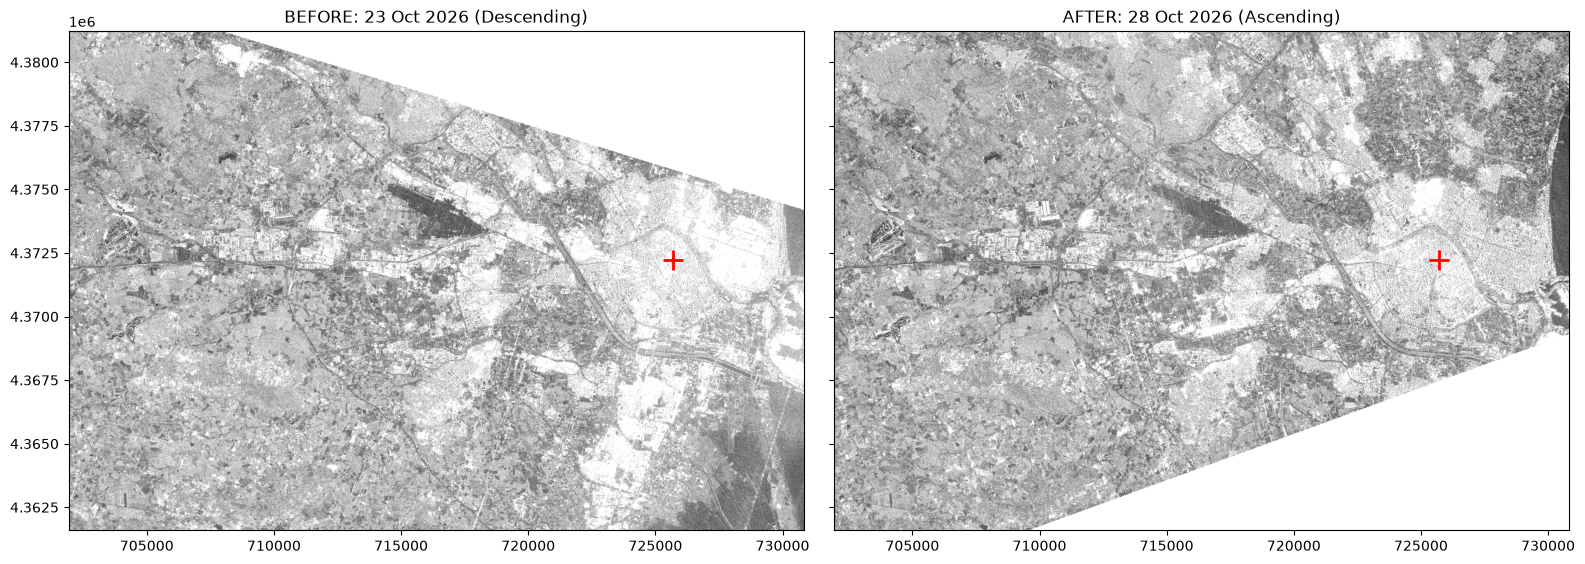

In [5]:
# Crop the AFTER image (28 Oct) with the SAME function and the SAME bbox
after_db, after_x, after_y, _ = read_crop(files[1], BBOX)

# Check both crops are on the same pixel grid
print("Same size:", before_db.shape == after_db.shape)
print("Same coordinates:", np.array_equal(crop_x, after_x) and np.array_equal(crop_y, after_y))

# Draw them side by side
extent = [crop_x[0], crop_x[-1], crop_y[-1], crop_y[0]]
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharex=True, sharey=True)

axes[0].imshow(before_db, cmap="gray", vmin=-25, vmax=0, extent=extent)
axes[0].set_title("BEFORE: 23 Oct 2026 (Descending)")

axes[1].imshow(after_db, cmap="gray", vmin=-25, vmax=0, extent=extent)
axes[1].set_title("AFTER: 28 Oct 2026 (Ascending)")

for ax in axes:
    ax.plot(city_x, city_y, "r+", markersize=15, markeredgewidth=2)

plt.tight_layout()
plt.show()

Pixels with data in both images: 71.3 %
Darker by more than 3 dB  : 25.0 %
Brighter by more than 3 dB: 14.6 %
Median change: -0.65 dB


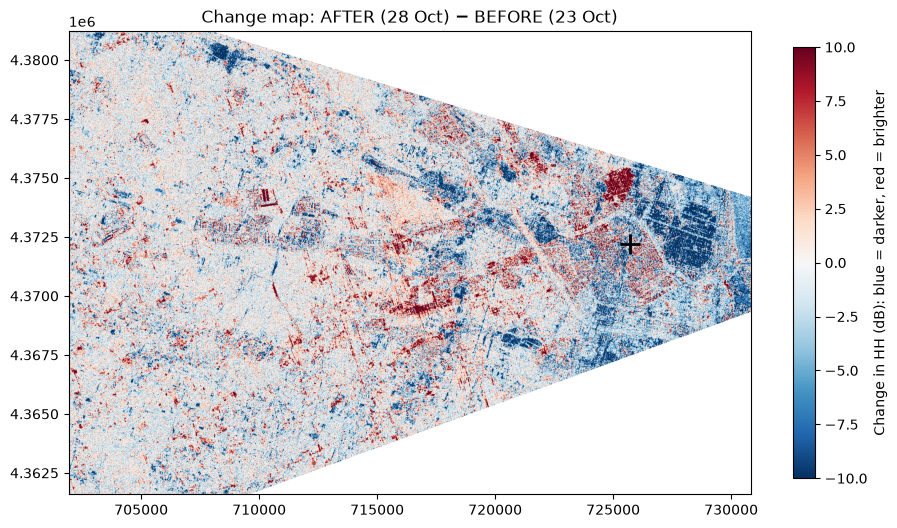

In [6]:
# Pixel-by-pixel change in dB (negative = darker after, positive = brighter after)
diff_db = after_db - before_db

# Keep only pixels where BOTH images have data
valid = np.isfinite(diff_db)
print("Pixels with data in both images:", round(valid.mean() * 100, 1), "%")
print("Darker by more than 3 dB  :", round((diff_db[valid] < -3).mean() * 100, 1), "%")
print("Brighter by more than 3 dB:", round((diff_db[valid] > 3).mean() * 100, 1), "%")
print("Median change:", round(float(np.nanmedian(diff_db)), 2), "dB")

plt.figure(figsize=(11, 8))
plt.imshow(diff_db, cmap="RdBu_r", vmin=-10, vmax=10, extent=extent)
plt.colorbar(label="Change in HH (dB): blue = darker, red = brighter", shrink=0.7)
plt.plot(city_x, city_y, "k+", markersize=15, markeredgewidth=2)
plt.title("Change map: AFTER (28 Oct) − BEFORE (23 Oct)")
plt.show()

AFTER filter -> darker by > 3 dB  : 13.4 %
AFTER filter -> brighter by > 3 dB: 5.1 %


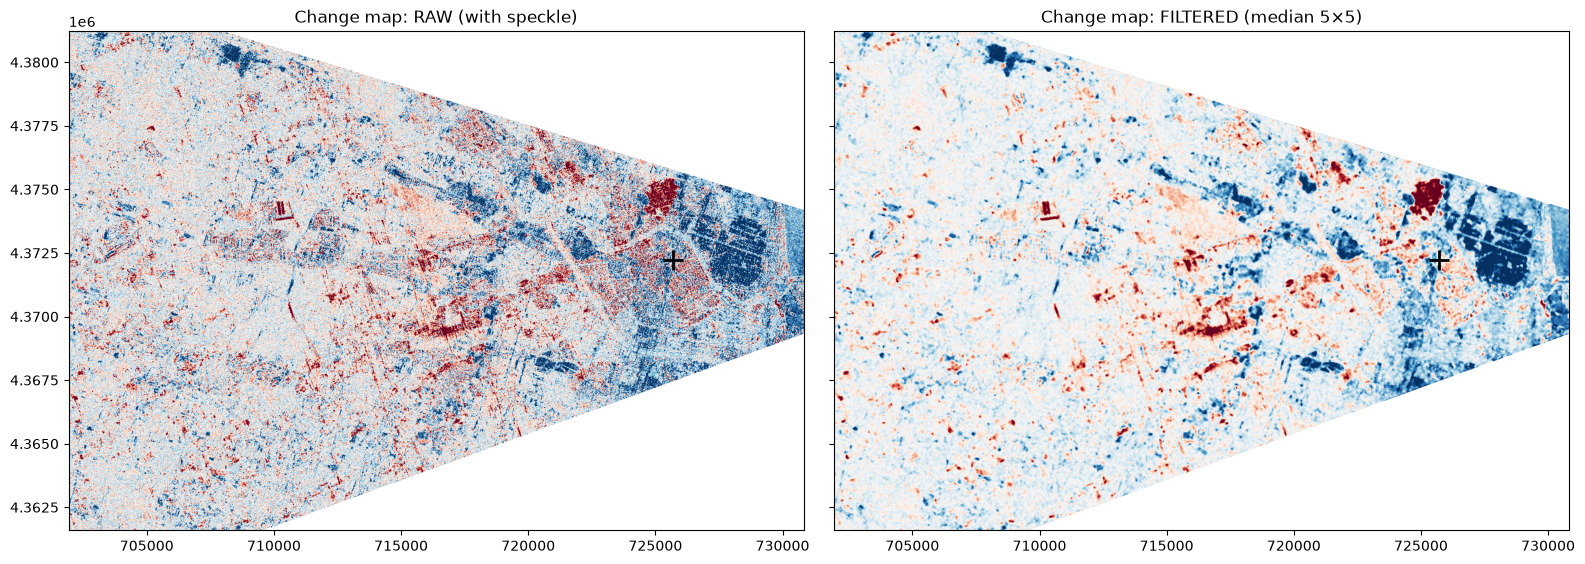

In [7]:
from scipy.ndimage import median_filter

def despeckle(img_db, size=5):
    """Reduce radar speckle with a median filter. Empty pixels (NaN) stay empty."""
    empty = np.isnan(img_db)
    filled = np.where(empty, np.nanmedian(img_db), img_db)   # the filter cannot handle NaN
    smooth = median_filter(filled, size=size)
    smooth[empty] = np.nan                                   # put the empty pixels back
    return smooth

before_smooth = despeckle(before_db)
after_smooth = despeckle(after_db)
diff_smooth = after_smooth - before_smooth

valid = np.isfinite(diff_smooth)
print("AFTER filter -> darker by > 3 dB  :", round((diff_smooth[valid] < -3).mean() * 100, 1), "%")
print("AFTER filter -> brighter by > 3 dB:", round((diff_smooth[valid] > 3).mean() * 100, 1), "%")

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharex=True, sharey=True)
axes[0].imshow(diff_db, cmap="RdBu_r", vmin=-10, vmax=10, extent=extent)
axes[0].set_title("Change map: RAW (with speckle)")
axes[1].imshow(diff_smooth, cmap="RdBu_r", vmin=-10, vmax=10, extent=extent)
axes[1].set_title("Change map: FILTERED (median 5×5)")
for ax in axes:
    ax.plot(city_x, city_y, "k+", markersize=15, markeredgewidth=2)
plt.tight_layout()
plt.show()

Otsu threshold (city crop only): -5.21 dB
Pixels classified as water: 72.6 %


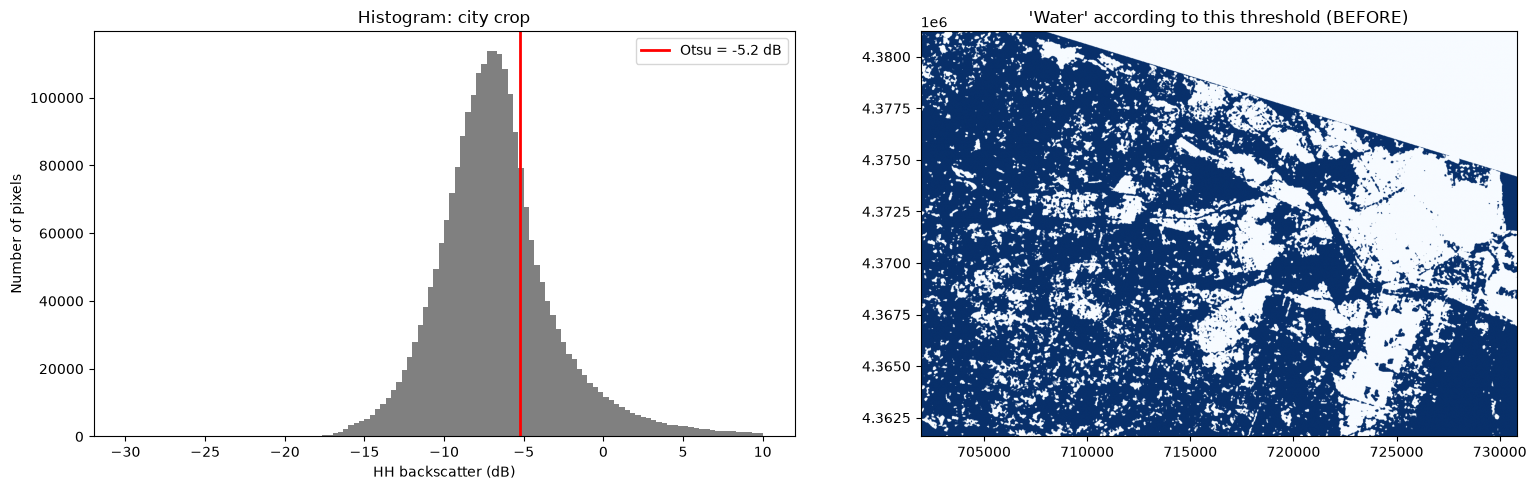

In [8]:
from skimage.filters import threshold_otsu

# All valid pixels of BOTH smoothed images together (same threshold for both = fair comparison)
all_pixels = np.concatenate([before_smooth[np.isfinite(before_smooth)],
                             after_smooth[np.isfinite(after_smooth)]])

threshold_city = threshold_otsu(all_pixels)
print("Otsu threshold (city crop only):", round(float(threshold_city), 2), "dB")
print("Pixels classified as water:", round((all_pixels < threshold_city).mean() * 100, 1), "%")

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Left: histogram + threshold line
axes[0].hist(all_pixels, bins=120, range=(-30, 10), color="gray")
axes[0].axvline(threshold_city, color="red", linewidth=2, label=f"Otsu = {threshold_city:.1f} dB")
axes[0].set_xlabel("HH backscatter (dB)")
axes[0].set_ylabel("Number of pixels")
axes[0].set_title("Histogram: city crop")
axes[0].legend()

# Right: what this threshold calls "water"
axes[1].imshow(before_smooth < threshold_city, cmap="Blues", extent=extent)
axes[1].set_title("'Water' according to this threshold (BEFORE)")

plt.tight_layout()
plt.show()

Otsu on wide area: -12.19 dB
Final water threshold: -15.0 dB
Water BEFORE: 0.55 %
Water AFTER : 0.54 %
NEW water   : 0.42 %


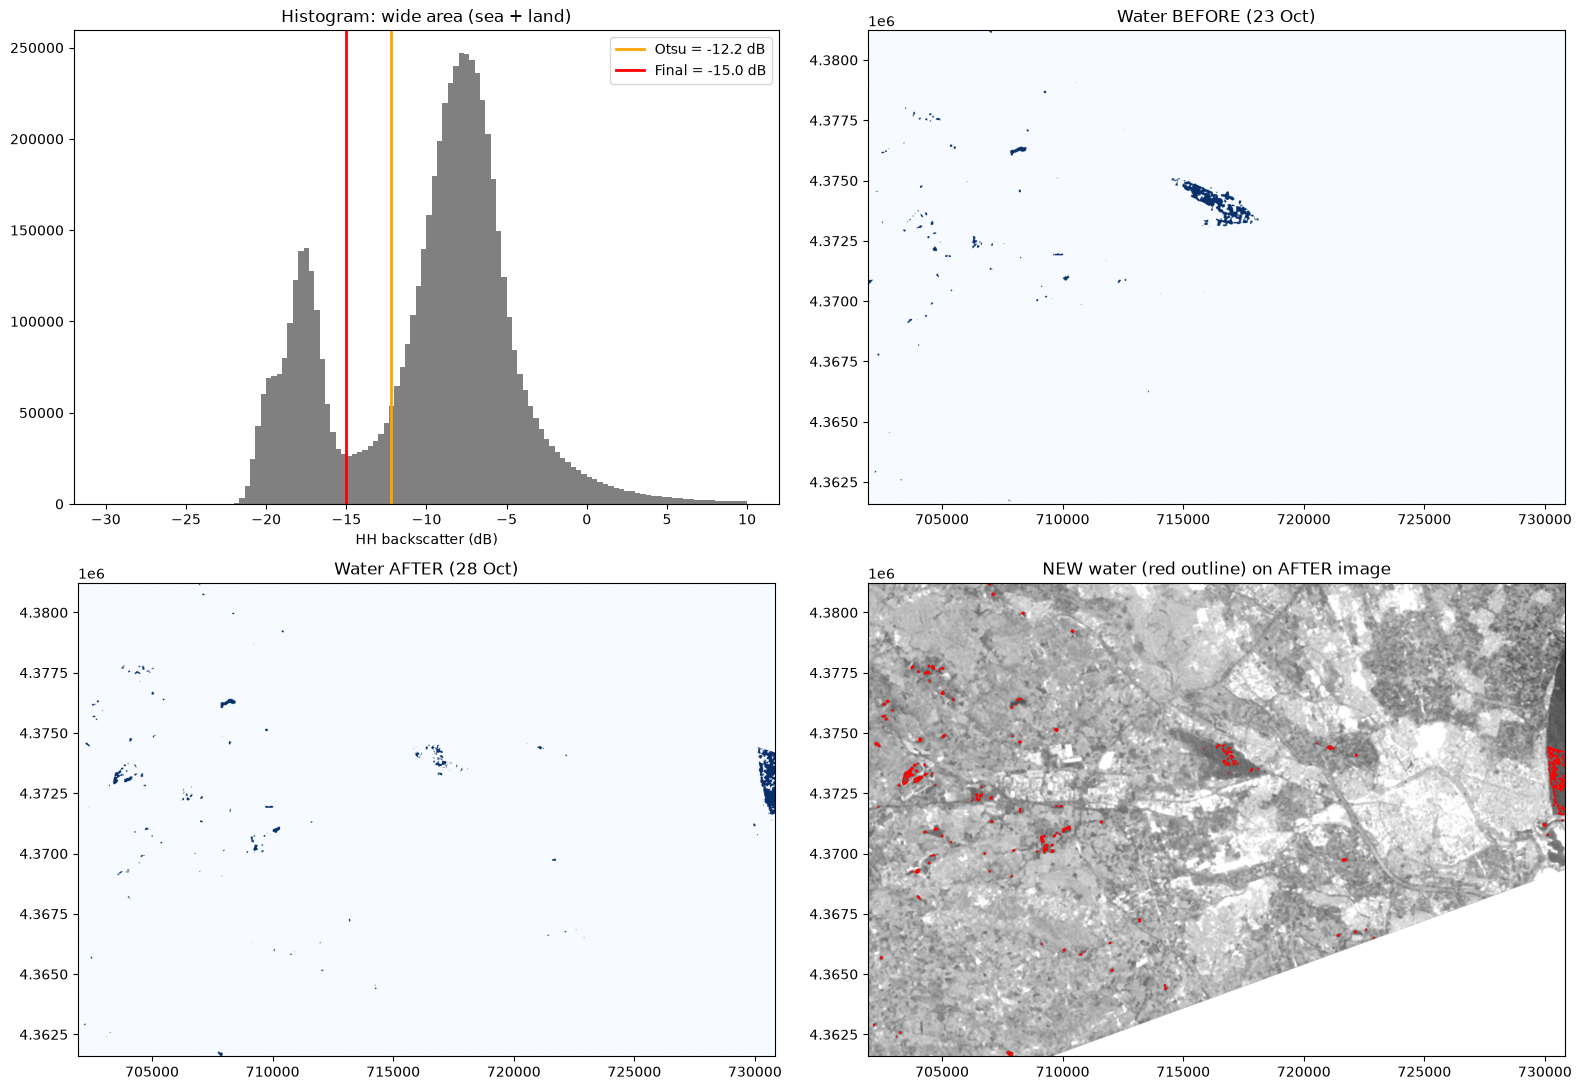

In [9]:
# 1. Learn the threshold on a WIDE area that contains the sea (both water and land present)
WIDE_BBOX = (-0.70, 39.25, -0.15, 39.60)
wide_before, _, _, _ = read_crop(files[0], WIDE_BBOX)
wide_after, _, _, _ = read_crop(files[1], WIDE_BBOX)
wide_before, wide_after = despeckle(wide_before), despeckle(wide_after)

wide_pixels = np.concatenate([wide_before[np.isfinite(wide_before)],
                              wide_after[np.isfinite(wide_after)]])
otsu_wide = threshold_otsu(wide_pixels)

# 2. Physics guardrail: calm water in L-band HH is usually below about -15 dB
WATER_MAX_DB = -15.0
water_threshold = min(otsu_wide, WATER_MAX_DB)
print("Otsu on wide area:", round(float(otsu_wide), 2), "dB")
print("Final water threshold:", round(float(water_threshold), 2), "dB")

# 3. Apply the threshold to the CITY crop (only where both images have data)
both_valid = np.isfinite(before_smooth) & np.isfinite(after_smooth)
water_before = (before_smooth < water_threshold) & both_valid
water_after = (after_smooth < water_threshold) & both_valid
new_water = water_after & ~water_before        # water AFTER but not BEFORE = possible flood

n = both_valid.sum()
print("Water BEFORE:", round(water_before.sum() / n * 100, 2), "%")
print("Water AFTER :", round(water_after.sum() / n * 100, 2), "%")
print("NEW water   :", round(new_water.sum() / n * 100, 2), "%")

# 4. Plots
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

axes[0, 0].hist(wide_pixels, bins=120, range=(-30, 10), color="gray")
axes[0, 0].axvline(otsu_wide, color="orange", linewidth=2, label=f"Otsu = {otsu_wide:.1f} dB")
axes[0, 0].axvline(water_threshold, color="red", linewidth=2, label=f"Final = {water_threshold:.1f} dB")
axes[0, 0].set_title("Histogram: wide area (sea + land)")
axes[0, 0].set_xlabel("HH backscatter (dB)")
axes[0, 0].legend()

axes[0, 1].imshow(water_before, cmap="Blues", extent=extent)
axes[0, 1].set_title("Water BEFORE (23 Oct)")

axes[1, 0].imshow(water_after, cmap="Blues", extent=extent)
axes[1, 0].set_title("Water AFTER (28 Oct)")

axes[1, 1].imshow(after_smooth, cmap="gray", vmin=-25, vmax=0, extent=extent)
axes[1, 1].contour(new_water, levels=[0.5], colors="red", linewidths=1,
                   extent=[crop_x[0], crop_x[-1], crop_y[0], crop_y[-1]])
axes[1, 1].set_title("NEW water (red outline) on AFTER image")

plt.tight_layout()
plt.show()


New size: (853, 1585)
Bounds (south, west, north, east): [39.3729, -0.6557, 39.5571, -0.3135]


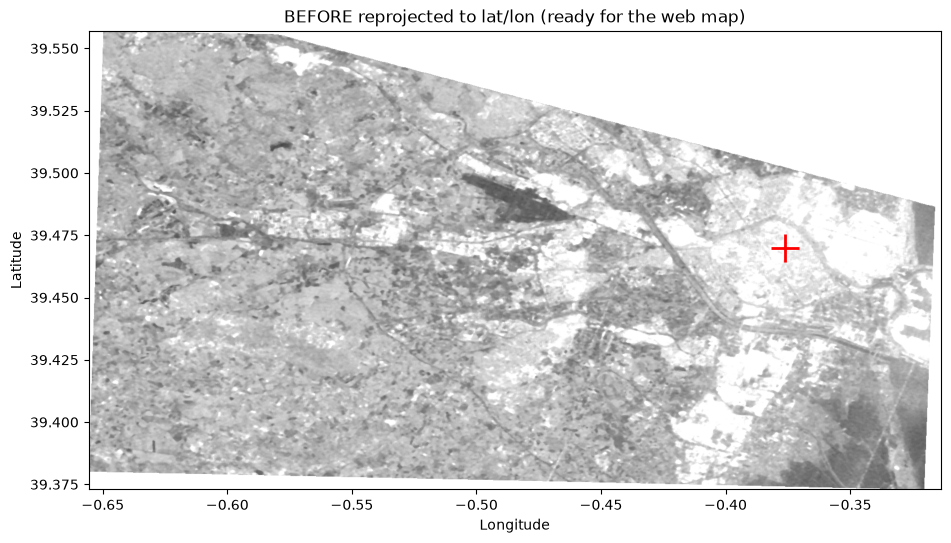

In [10]:
from rasterio.transform import from_origin
from rasterio.warp import calculate_default_transform, reproject, Resampling

def reproject_to_latlon(img, x, y, epsg, resampling=Resampling.bilinear):
    """Reproject a UTM image (pixel centers x, y) to lat/lon (EPSG:4326).
    Returns the new image and its bounds (south, west, north, east)."""
    pixel = abs(x[1] - x[0])                          # 20 m
    height, width = img.shape
    left, top = x[0] - pixel / 2, y[0] + pixel / 2    # outer edge, not pixel center
    right, bottom = left + width * pixel, top - height * pixel
    src_transform = from_origin(left, top, pixel, pixel)

    # Compute the size and position of the new lat/lon image
    dst_transform, dst_width, dst_height = calculate_default_transform(
        f"EPSG:{epsg}", "EPSG:4326", width, height, left, bottom, right, top)

    out = np.full((dst_height, dst_width), np.nan, dtype="float32")
    reproject(source=img.astype("float32"), destination=out,
              src_transform=src_transform, src_crs=f"EPSG:{epsg}",
              dst_transform=dst_transform, dst_crs="EPSG:4326",
              src_nodata=np.nan, dst_nodata=np.nan, resampling=resampling)

    west, north = dst_transform * (0, 0)
    east, south = dst_transform * (dst_width, dst_height)
    return out, (south, west, north, east)

# Test on the BEFORE image
before_ll, bounds = reproject_to_latlon(before_smooth, crop_x, crop_y, epsg)
south, west, north, east = bounds
print("New size:", before_ll.shape)
print("Bounds (south, west, north, east):", [round(v, 4) for v in bounds])

plt.figure(figsize=(11, 7))
plt.imshow(before_ll, cmap="gray", vmin=-25, vmax=0, extent=[west, east, south, north])
plt.plot(-0.3763, 39.4699, "r+", markersize=20, markeredgewidth=2)
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("BEFORE reprojected to lat/lon (ready for the web map)")
plt.show()

In [11]:
import os
from PIL import Image
from matplotlib import colormaps

OUT_DIR = "../public/data/valencia"
os.makedirs(OUT_DIR, exist_ok=True)

def gray_rgba(img_db, vmin=-25, vmax=0):
    """Radar image -> grayscale RGBA. Empty pixels become transparent."""
    scaled = np.clip((img_db - vmin) / (vmax - vmin), 0, 1)
    gray = (np.nan_to_num(scaled) * 255).astype("uint8")
    alpha = np.where(np.isnan(img_db), 0, 255).astype("uint8")
    return np.dstack([gray, gray, gray, alpha])

def colormap_rgba(img, cmap_name, vmin, vmax):
    """Any image -> colored RGBA using a matplotlib colormap. Empty pixels become transparent."""
    scaled = np.clip((img - vmin) / (vmax - vmin), 0, 1)
    rgba = (colormaps[cmap_name](np.nan_to_num(scaled)) * 255).astype("uint8")
    rgba[..., 3] = np.where(np.isnan(img), 0, 255)
    return rgba

# Water classes: 0 = no water, 1 = permanent water, 2 = new water, 3 = water gone
water_class = np.full(before_smooth.shape, np.nan, dtype="float32")
water_class[both_valid] = 0
water_class[water_before & water_after] = 1
water_class[water_after & ~water_before] = 2
water_class[water_before & ~water_after] = 3

CLASS_COLORS = {1: (30, 120, 255, 200),   # blue   = permanent water
                2: (230, 30, 30, 230),    # red    = new water
                3: (255, 165, 0, 200)}    # orange = water gone

def classes_rgba(classes):
    rgba = np.zeros(classes.shape + (4,), dtype="uint8")   # fully transparent by default
    for value, color in CLASS_COLORS.items():
        rgba[classes == value] = color
    return rgba

# Reproject everything to lat/lon (same input grid -> same bounds for all layers)
before_ll, bounds = reproject_to_latlon(before_smooth, crop_x, crop_y, epsg)
after_ll, _ = reproject_to_latlon(after_smooth, crop_x, crop_y, epsg)
change_ll, _ = reproject_to_latlon(diff_smooth, crop_x, crop_y, epsg)
class_ll, _ = reproject_to_latlon(water_class, crop_x, crop_y, epsg, resampling=Resampling.nearest)

Image.fromarray(gray_rgba(before_ll)).save(f"{OUT_DIR}/before.png")
Image.fromarray(gray_rgba(after_ll)).save(f"{OUT_DIR}/after.png")
Image.fromarray(colormap_rgba(change_ll, "RdBu_r", -10, 10)).save(f"{OUT_DIR}/change.png")
Image.fromarray(classes_rgba(class_ll)).save(f"{OUT_DIR}/water.png")

for name in ["before.png", "after.png", "change.png", "water.png"]:
    print(name, os.path.getsize(f"{OUT_DIR}/{name}") // 1024, "KB")
print("Bounds (south, west, north, east):", [round(v, 4) for v in bounds])

before.png 907 KB
after.png 928 KB
change.png 1729 KB
water.png 12 KB
Bounds (south, west, north, east): [39.3729, -0.6557, 39.5571, -0.3135]


In [12]:
import json

def scene_info(path, role):
    """Identity card of one NISAR scene, read from the file itself."""
    with h5py.File(path, "r") as nisar:
        ident = nisar["science/LSAR/identification"]
        return {
            "role": role,
            "granule": path.split("/")[-1].replace(".h5", ""),
            "datetime_utc": read_text(ident["zeroDopplerStartTime"])[:19] + "Z",
            "track": int(read_text(ident["trackNumber"])),
            "frame": int(read_text(ident["frameNumber"])),
            "direction": read_text(ident["orbitPassDirection"]),
            "polarization": "HH",
            "product": "NISAR L2 GCOV, L-band, frequency A (20 m)",
        }

# Rain between the two scenes (from weather.json made earlier)
with open(f"{OUT_DIR}/weather.json") as f:
    rain_mm = json.load(f)["total_precipitation_mm"]

def pct(mask):
    return round(float(mask.sum() / both_valid.sum() * 100), 2)

south, west, north, east = bounds
metadata = {
    "zone": "valencia",
    "name": "Valencia, Spain",
    "label": "real NISAR data",
    "bounds": [[round(south, 6), round(west, 6)], [round(north, 6), round(east, 6)]],
    "crs": "EPSG:4326",
    "scenes": [scene_info(files[0], "before"), scene_info(files[1], "after")],
    "layers": {
        "before": {"file": "before.png", "description": "HH backscatter, BEFORE", "range_db": [-25, 0]},
        "after":  {"file": "after.png",  "description": "HH backscatter, AFTER",  "range_db": [-25, 0]},
        "change": {"file": "change.png", "description": "AFTER - BEFORE (blue = darker, red = brighter)",
                   "range_db": [-10, 10]},
        "water":  {"file": "water.png", "description": "Water detected by Otsu + physics rule",
                   "legend": {"permanent_water": "#1e78ff", "new_water": "#e61e1e", "water_gone": "#ffa500"}},
    },
    "processing": {
        "speckle_filter": "median 5x5",
        "otsu_threshold_db": round(float(otsu_wide), 2),
        "water_threshold_db": float(water_threshold),
        "threshold_rule": "min(Otsu on a wide area including the sea, -15 dB)",
    },
    "results": {
        "water_before_pct": pct(water_before),
        "water_after_pct": pct(water_after),
        "new_water_pct": pct(water_after & ~water_before),
        "water_gone_pct": pct(water_before & ~water_after),
        "rain_between_scenes_mm": rain_mm,
        "conclusion": "No flood: no large new water area, and almost no rain between the two dates.",
    },
    "notes": [
        "The two scenes have different viewing geometry (Descending vs Ascending): "
        "buildings and smooth surfaces (airport) can change brightness without any real surface change.",
        "Dark does not always mean water: smooth surfaces like runways also look dark.",
    ],
    "source": "NISAR data courtesy of NASA/JPL-Caltech and ISRO, distributed by ASF DAAC.",
    "weather_source": "Open-Meteo Historical Weather API",
}

with open(f"{OUT_DIR}/metadata.json", "w") as f:
    json.dump(metadata, f, indent=2, ensure_ascii=False)

print(json.dumps(metadata, indent=2, ensure_ascii=False))

{
  "zone": "valencia",
  "name": "Valencia, Spain",
  "label": "real NISAR data",
  "bounds": [
    [
      39.372934,
      -0.655672
    ],
    [
      39.557102,
      -0.313461
    ]
  ],
  "crs": "EPSG:4326",
  "scenes": [
    {
      "role": "before",
      "granule": "NISAR_L2_PR_GCOV_033_167_D_069_2005_DHDH_A_20261023T190137_20261023T190212_P05036_N_F_J_001",
      "datetime_utc": "2026-10-23T19:01:37Z",
      "track": 167,
      "frame": 69,
      "direction": "Descending",
      "polarization": "HH",
      "product": "NISAR L2 GCOV, L-band, frequency A (20 m)"
    },
    {
      "role": "after",
      "granule": "NISAR_L2_PR_GCOV_034_058_A_022_2005_DHDH_A_20261028T050718_20261028T050753_P05036_N_F_J_001",
      "datetime_utc": "2026-10-28T05:07:18Z",
      "track": 58,
      "frame": 22,
      "direction": "Ascending",
      "polarization": "HH",
      "product": "NISAR L2 GCOV, L-band, frequency A (20 m)"
    }
  ],
  "layers": {
    "before": {
      "file": "before.png",


In [13]:
import warnings

FACTOR = 4   # 4 x 4 pixels of 20 m -> one cell of 80 m

def block_median(img, factor):
    """Shrink an image by taking the median of each factor x factor block (NaN ignored)."""
    rows = img.shape[0] // factor * factor          # drop the last rows/cols that don't fill a block
    cols = img.shape[1] // factor * factor
    blocks = img[:rows, :cols].reshape(rows // factor, factor, cols // factor, factor)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)   # blocks that are fully empty -> NaN, no warning
        return np.nanmedian(blocks, axis=(1, 3)), rows, cols

# before_ll / after_ll are the lat/lon images from Cellule 11
before_grid, used_rows, used_cols = block_median(before_ll, FACTOR)
after_grid, _, _ = block_median(after_ll, FACTOR)

# Bounds change a little because we dropped the last rows/cols
south, west, north, east = bounds
lat_step = (north - south) / before_ll.shape[0]
lon_step = (east - west) / before_ll.shape[1]
grid_south = north - used_rows * lat_step
grid_east = west + used_cols * lon_step

def to_json_list(arr):
    """2D numpy array -> list of lists, NaN -> null, 1 decimal."""
    return [[None if np.isnan(v) else round(float(v), 1) for v in row] for row in arr]

grid = {
    "zone": "valencia",
    "label": "real NISAR data",
    "bounds": [[round(grid_south, 6), round(west, 6)], [round(north, 6), round(grid_east, 6)]],
    "shape": list(before_grid.shape),
    "cell_size_m": 20 * FACTOR,
    "row_order": "north_to_south",
    "threshold_db": float(water_threshold),
    "before_db": to_json_list(before_grid),
    "after_db": to_json_list(after_grid),
}

with open(f"{OUT_DIR}/grid.json", "w") as f:
    json.dump(grid, f, separators=(",", ":"))      # compact: no spaces -> smaller file

print("Grid shape:", before_grid.shape, "| file size:", os.path.getsize(f"{OUT_DIR}/grid.json") // 1024, "KB")

# Quick test: read the values at a lat/lon, exactly like SARah will do
def lookup(grid, lat, lon):
    (s, w), (n, e) = grid["bounds"]
    rows, cols = grid["shape"]
    r = int((n - lat) / (n - s) * rows)
    c = int((lon - w) / (e - w) * cols)
    return grid["before_db"][r][c], grid["after_db"][r][c]

print("City center (before, after):", lookup(grid, 39.4699, -0.3763))
print("Airport     (before, after):", lookup(grid, 39.4893, -0.4816))

Grid shape: (213, 396) | file size: 838 KB
City center (before, after): (-1.9, -4.2)
Airport     (before, after): (-16.3, -14.4)
